In [79]:
# Daten einlesen
import pandas as pd
import numpy as np
import sklearn
import sklearn.datasets
import sklearn.ensemble
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report

columns = ["Age", "Workclass", "fnlwgt", "Education", "Education-Num", "Marital Status","Occupation", "Relationship", "Race", "Sex", "Capital Gain", "Capital Loss","Hours per week", "Country", "income"]


df = pd.read_csv("adult.data", header=None, names=columns, skipinitialspace=True, na_values="?")
print(df["income"].value_counts())



income
<=50K    24720
>50K      7841
Name: count, dtype: int64


In [80]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

# Datenbereinigung
df["income"] = income_col.astype(int)

 
print("Klassenverteilung:", df["income"].value_counts().to_dict())

categorical_cols = ["Workclass", "Education", "Marital Status", "Occupation", "Relationship", "Race", "Sex", "Country"]

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])
 
feature_names = [c for c in columns if c != "income"]
X = df[feature_names].values.astype(np.float32)
y = df["income"].values.astype(np.float32)
 
# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
 
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype(np.float32)
X_test_s  = scaler.transform(X_test).astype(np.float32)
 
print(f"Train: {X_train_s.shape}, Test: {X_test_s.shape}")

Klassenverteilung: {0: 24720, 1: 7841}
Train: (26048, 14), Test: (6513, 14)


In [81]:
#Neuronales Netz
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    X_train_s,
    y_train,
    epochs=15,           
    batch_size=256,
    validation_split=0.1,
    verbose=1
)
y_pred = (model.predict(X_test_s, verbose=0) > 0.5).astype(int).flatten()
print("\nTest-Ergebnisse:")
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"]))


Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7816 - loss: 0.4630 - val_accuracy: 0.8334 - val_loss: 0.3725
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8330 - loss: 0.3626 - val_accuracy: 0.8372 - val_loss: 0.3380
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8415 - loss: 0.3373 - val_accuracy: 0.8445 - val_loss: 0.3275
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8449 - loss: 0.3295 - val_accuracy: 0.8453 - val_loss: 0.3232
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8470 - loss: 0.3261 - val_accuracy: 0.8495 - val_loss: 0.3207
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8477 - loss: 0.3241 - val_accuracy: 0.8499 - val_loss: 0.3214
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8487 - loss: 0.3219 - val_accuracy: 0.8476 - val_loss: 0.3182
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8490 - loss: 0.3203 - val_accuracy: 0.8488 - val_loss:

In [92]:
#LIME

def predict_fn_proba(x: np.ndarray) -> np.ndarray:
    p1 = model.predict(scaler.transform(x).astype(np.float32), verbose=0).flatten()
    return np.column_stack([1 - p1, p1])
 
def predict_fn_binary(x: np.ndarray) -> np.ndarray:
    return (predict_fn_proba(x)[:, 1] > 0.5).astype(int)
 
# Beispiel-Instanz
SAMPLE_IDX  = 0
sample_raw    = X_test[SAMPLE_IDX : SAMPLE_IDX + 1]
sample_scaled = X_test_s[SAMPLE_IDX : SAMPLE_IDX + 1]
 
print(f"\nBeispiel-Instanz (Index {SAMPLE_IDX}):")
print(pd.Series(sample_raw[0], index=feature_names))
print(f"Wahres Label : {int(y_test[SAMPLE_IDX])}")
print(f"Vorhersage   : {predict_fn_binary(sample_raw)[0]}")
 

print("\n=== 3. LIME ===")
import lime
import lime.lime_tabular

lime_explainer = lime.lime_tabular.LimeTabularExplainer(training_data=X_train,
    feature_names=feature_names,class_names=["<=50K", ">50K"],
    mode="classification",random_state=42)
 
lime_exp  = lime_explainer.explain_instance(
    data_row=sample_raw[0],
    predict_fn=predict_fn_proba,
    num_features=14
)

import matplotlib.pyplot as plt

fig = lime_exp.as_pyplot_figure()
fig.savefig("lime_explanation.png", bbox_inches="tight")



Beispiel-Instanz (Index 0):
Age                   31.0
Workclass              4.0
fnlwgt            117963.0
Education             10.0
Education-Num         16.0
Marital Status         4.0
Occupation             9.0
Relationship           3.0
Race                   4.0
Sex                    1.0
Capital Gain           0.0
Capital Loss           0.0
Hours per week        40.0
Country               38.0
dtype: float32
Wahres Label : 0
Vorhersage   : 0

=== 3. LIME ===


In [83]:
# ANCHORS
from anchor import anchor_tabular

cat_idx = [feature_names.index(c) for c in categorical_cols if c in feature_names]
anchor_explainer = anchor_tabular.AnchorTabularExplainer(
    class_names=["<=50K", ">50K"],
    feature_names=feature_names,
    train_data=X_train,
    categorical_names={i: [str(v) for v in sorted(set(X_train[:, i].astype(int)))]
                       for i in cat_idx}
)
 
anchor_exp       = anchor_explainer.explain_instance(
    sample_raw[0], predict_fn_binary, threshold=0.95
)
anchor_rules     = anchor_exp.names()
anchor_precision = anchor_exp.precision()
anchor_coverage  = anchor_exp.coverage()
 
print('Anchor: %s' % (' AND '.join(anchor_exp.names())))
print('Precision: %.2f' % anchor_exp.precision())
print('Coverage: %.2f' % anchor_exp.coverage())

Anchor: Marital Status = 4 AND Relationship = 3
Precision: 1.00
Coverage: 0.13


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 950us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 874us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 865us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 945us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 912us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 887us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 897us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 862us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 880us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 862us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 877us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34

/tmp/ipykernel_1016563/929773850.py:29: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

... (11 outputs left out)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

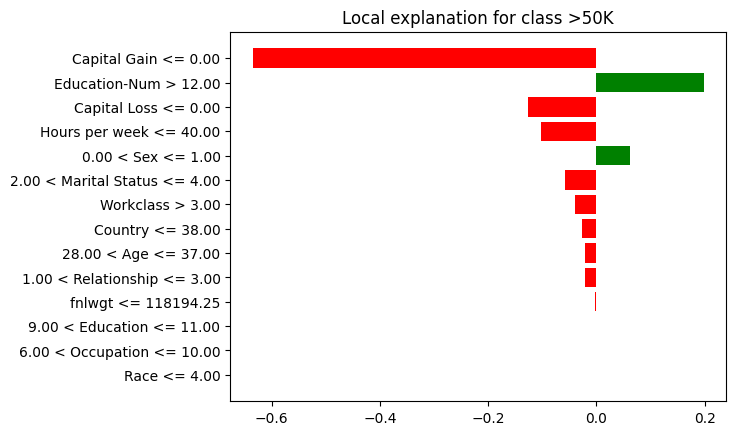

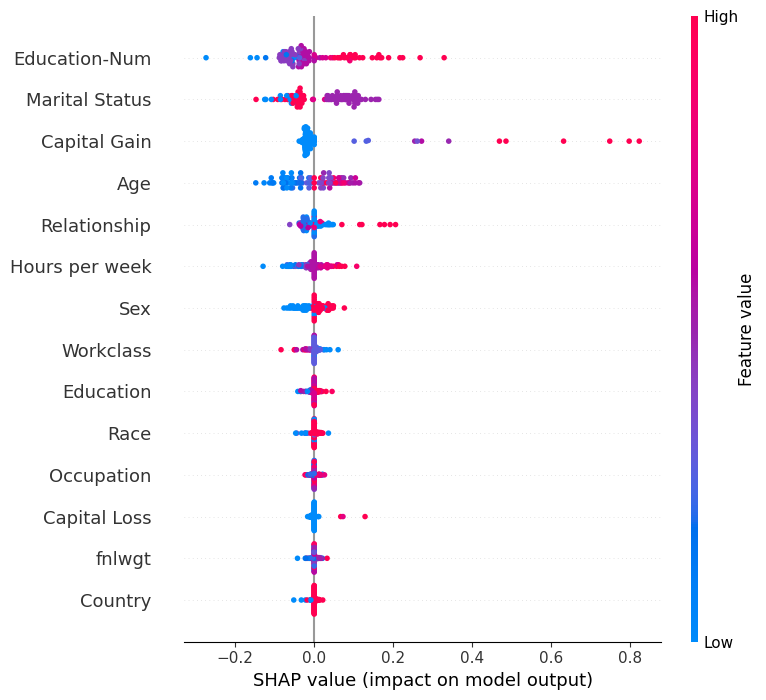

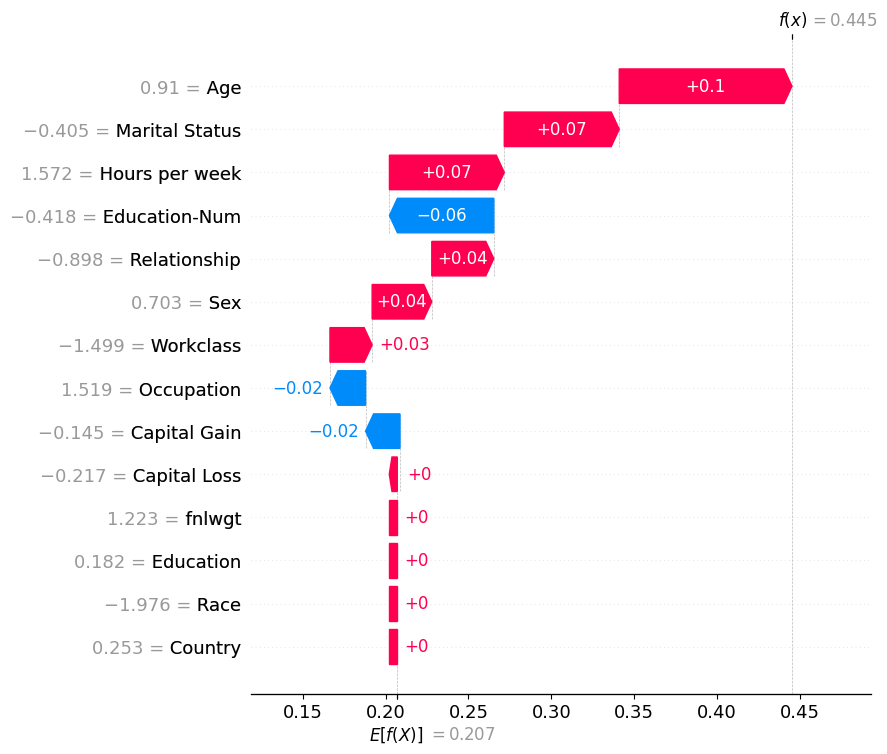

In [ ]:
#SHAP
import shap
shap.initjs()
# Wrapper-Funktion für das Keras-Modell
def model_f(x):
    return model.predict(x).flatten()
# Hintergrunddaten  wählen
np.random.seed(42)
K_background, K_test = 100  
background = shap.sample(X_train_s, K_background,
 random_state=42)
X_test_sample = shap.sample(X_test_s, K_test,
 random_state=42)
explainer = shap.KernelExplainer(model_f, background)
shap_values = explainer.shap_values(X_test_sample, 
nsamples=100)
shap_values = np.array(shap_values)  
if shap_values.ndim == 3:
    shap_values = shap_values[0]
# Beeswarm-Plot 
plt.figure()
shap.summary_plot(shap_values,X_test_sample,
feature_names=feature_names)
# Waterfall-Plot für eine einzelne Beobachtung
i = 0  
expl = shap.Explanation(values=shap_values[i],
 base_values=explainer.expected_value,
    data=X_test_sample[i], feature_names=feature_names)
plt.figure()
shap.plots.waterfall(expl, max_display=15)
plt.show()


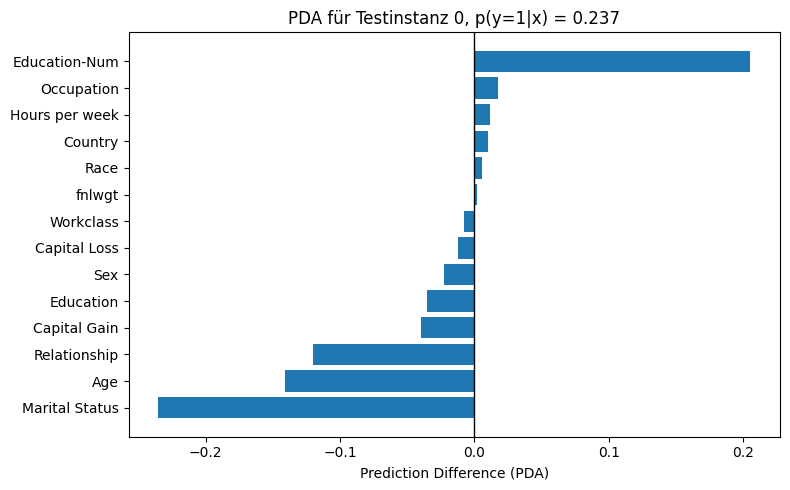

In [ ]:
# PDA für EINEN Datenpunkt 
def pda_for_instance(model, x0, X_background, n_samples=200, batch_size=256, target_class=0):
    # Originalvorhersage p(y=1| x0)
    p0_vec = model.predict(x0[None, :], verbose=0)  
    p0 = float(p0_vec[0, 0])
    n_features = x0.shape[0]
    scores = np.zeros(n_features, dtype=np.float32)

    rng = np.random.default_rng(42)
    # Für jedes Feature j: marginalisiere es aus
    for j in range(n_features):
        # a) Werte für Feature j aus Trainingsverteilung ziehen
        idx = rng.integers(0, X_background.shape[0], size=n_samples)
        sampled_vals = X_background[idx, j]  

        # b) Kopien von x0, in denen nur Feature j ersetzt wird
        X_perturbed = np.repeat(x0[None, :], n_samples, axis=0)
        X_perturbed[:, j] = sampled_vals

        # c) Vorhersagen für die gestörten Samples
        preds = model.predict(
            X_perturbed,
            verbose=0,
            batch_size=batch_size)[:, 0]  # (n_samples,)

        # d) Erwartete Vorhersage nach Marginalisierung
        p_bar = preds.mean()

        # e) Prediction Difference (Unterstützung des Features)
        scores[j] = p0 - p_bar

    return scores, p0

# Beispiel: PDA für eine Testinstanz + Plot
i = 0
x0 = X_test_s[i]          # shape (n_features,)
background = X_train_s    # Trainingsdaten als Verteilungs-Schätzer
pda_scores, p0 = pda_for_instance(model,x0,background,n_samples=200,   batch_size=256)
# Sortiert nach Wichtigkeit 
feature_names_arr = np.array(feature_names)
order = np.argsort(pda_scores)[::-1]

plt.figure(figsize=(8, 5))
plt.barh(feature_names_arr[order], pda_scores[order])
plt.axvline(0, color="black", linewidth=1)
plt.gca().invert_yaxis()
plt.xlabel("Prediction Difference (PDA)")
plt.title(f"PDA für Testinstanz {i}, p(y=1|x) = {p0:.3f}")
plt.tight_layout()
plt.show()

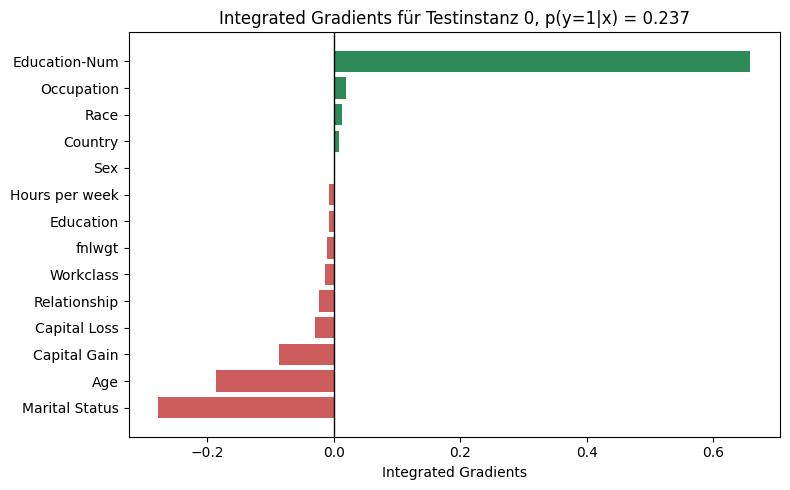

In [ ]:
#INTEGRATED GRADIENTS
import tensorflow as tf

def integrated_gradients(model,x, baseline=None, m_steps=50):
    """
    Integrated Gradients nach:
    IG(x) ≈ (x - baseline) * 1/m Σ_k ∂F(x_k)/∂x, 
    x_k = baseline + (k/m) * (x - baseline)
    """
    x = tf.convert_to_tensor(x, dtype=tf.float32)  
    x = tf.reshape(x, (1, -1))                   

    baseline = tf.convert_to_tensor(baseline, dtype=tf.float32)
    baseline = tf.reshape(baseline, (1, -1))
    
    # Pfad zwischen baseline und x
    alphas = tf.linspace(0.0, 1.0, m_steps + 1)  
    alphas_x = tf.reshape(alphas, (-1, 1))        
    path_inputs = baseline + alphas_x * (x - baseline)  

    # Gradienten entlang des Pfads
    with tf.GradientTape() as tape:
        tape.watch(path_inputs)
        preds = model(path_inputs, training=False)[:, 0]  
    grads = tape.gradient(preds, path_inputs)            
    grads_trap = (grads[:-1] + grads[1:]) / 2.0           
    avg_grads = tf.reduce_mean(grads_trap, axis=0)       
    # Integrated Gradients
    ig = (x - baseline)[0] * avg_grads                   
    return ig.numpy()

#Testinstanz
i = 0
x0 = X_test_s[i]  

# Baseline: Nullvektor 
baseline = np.mean(X_train_s, axis=0)
# IG berechnen
ig_attr = integrated_gradients(model, x0, baseline=baseline, m_steps=50)
# Vorhersage dazu
p0 = float(model.predict(x0[None, :], verbose=0)[0, 0])

# Visualisierung als Balkenplot
feature_names_arr = np.array(feature_names)
order = np.argsort(ig_attr)[::-1]  # wichtigste Features oben

plt.figure(figsize=(8, 5))
colors = ['seagreen' if val > 0 else 'indianred' for val in ig_attr[top_order]]
plt.barh(feature_names_arr[order], ig_attr[order], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.gca().invert_yaxis()
plt.xlabel("Integrated Gradients")
plt.title(f"Integrated Gradients für Testinstanz {i}, p(y=1|x) = {p0:.3f}")
plt.tight_layout()
plt.show()

Vorhersage p(y=1|x) für Instanz 0: 0.237
Summe der Relevanzen (sollte ~ Vorhersage sein): 0.23722115214134257


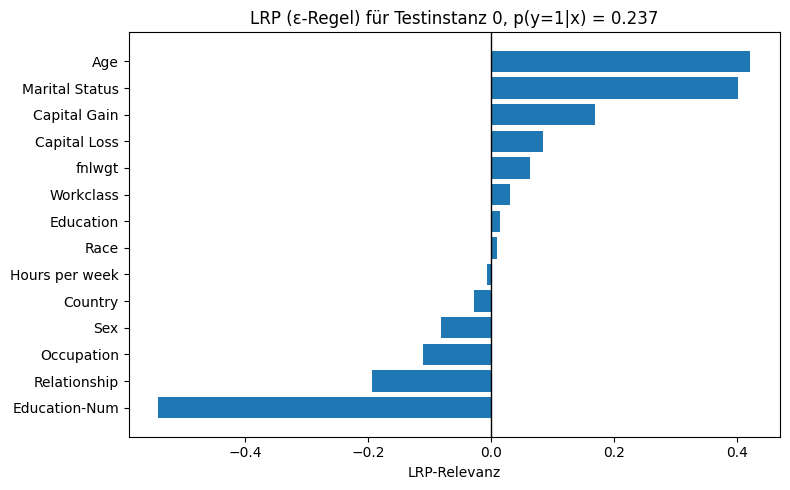

In [ ]:
#LRP

# Hilfsfunktion: ε-LRP für eine Dense-Schicht
def lrp_dense(R_out, W, b, a_in, eps=1e-6):
    """
    R_out : Relevanzen der Ausgänge (shape: (n_out,))
    W     : Gewichte (shape: (n_in, n_out))
    b     : Bias (wird hier ignoriert, wie in vielen LRP-Varianten)
    a_in  : Aktivierungen der Eingabe (shape: (n_in,))
    eps   : Stabilisierungskonstante (ε-LRP)

    Rückgabe:
        R_in : Relevanzen der Eingabe (shape: (n_in,))
    """
    # z_ij = a_i * w_ij
    z = a_in[:, None] * W  # (n_in, n_out)
    # Summen pro Ausgangsneuron
    z_sum = z.sum(axis=0, keepdims=True)  # (1, n_out)
    # Stabilisierung (ε-LRP)
    sign = np.where(z_sum >= 0, 1.0, -1.0)
    z_sum_stable = z_sum + eps * sign  # (1, n_out)
    # Anteil von i an j: (z_ij / sum_i z_ij) * R_j
    message = (z / z_sum_stable) * R_out  # Broadcasting über (n_in, n_out)
    # Relevanz der Eingabe-Neuronen
    R_in = message.sum(axis=1)  # (n_in,)
    return R_in

# LRP für das gesamtes Modell (eine Instanz)
def lrp_for_instance(model, x0, eps=1e-6):
    """
    model : dein trainiertes Keras-Modell
    x0    : 1D-Array einer Instanz im STANDARDISIERTEN Raum (X_test_s[i])
    eps   : ε für ε-LRP

    Rückgabe:
        R_input : Relevanzen für jedes Eingangsfeature (shape: (n_features,))
        y_pred  : Modellvorhersage (Skalar, p(y=1|x0))
    """
    # Forward-Pass, Aktivierungen speichern
    # a0: Eingabe
    a0 = x0.astype(np.float32)
    # Schicht 1 
    W1, b1 = model.layers[0].get_weights()  
    z1 = np.dot(a0, W1) + b1
    a1 = np.maximum(0, z1)  # ReLU
    # Schicht 2 
    W2, b2 = model.layers[1].get_weights()  
    z2 = np.dot(a1, W2) + b2
    a2 = np.maximum(0, z2)  # ReLU
    # Schicht 3 
    W3, b3 = model.layers[2].get_weights()  
    z3 = np.dot(a2, W3) + b3
    y_pred = 1.0 / (1.0 + np.exp(-z3))      
    y_pred = float(y_pred[0])              

    # Relevanz-Rückpropagation
    # Ausgangsrelevanz: Gesamte Vorhersage p(y=1|x0)
    R3 = np.array([y_pred], dtype=np.float32) 
    # Backprop durch letzte Dense-Schicht
    R2 = lrp_dense(R3, W3, b3, a2, eps=eps)  
    # Backprop durch zweite Dense-Schicht
    R1 = lrp_dense(R2, W2, b2, a1, eps=eps)   
    # Backprop auf Eingabe
    R0 = lrp_dense(R1, W1, b1, a0, eps=eps)   
    return R0, y_pred

# Beispiel: LRP für eine Testinstanz + Plot
i = 0
x0 = X_test_s[i]  
R_input, p0 = lrp_for_instance(model, x0, eps=1e-6)
print(f"Vorhersage p(y=1|x) für Instanz {i}: {p0:.3f}")
print("Summe der Relevanzen (sollte ~ Vorhersage sein):", R_input.sum())
feature_names_arr = np.array(feature_names)
order = np.argsort(R_input)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(feature_names_arr[order], R_input[order])
plt.axvline(0, color="black", linewidth=1)
plt.gca().invert_yaxis()
plt.xlabel("LRP-Relevanz")
plt.title(f"LRP (ε-Regel) für Testinstanz {i}, p(y=1|x) = {p0:.3f}")
plt.tight_layout()
plt.show()